[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DaTrollMon/schutz-gr-solutions-3rd/blob/main/Ch.3/Problem_3.34.ipynb)

# Chapter 3, Problem 34 — null coordinates $u = t - x$, $v = t + x$

**Problem.** Consider the coordinates $u = t - x$, $v = t + x$ in Minkowski space.
- **(a)** Define $\vec e_u$ to be the vector connecting the events with coordinates $\{u = 1, v = 0, y = 0, z = 0\}$ and $\{u = 0, v = 0, y = 0, z = 0\}$, and analogously for $\vec e_v$. Show that $\vec e_u = (\vec e_t - \vec e_x)/2$, $\vec e_v = (\vec e_t + \vec e_x)/2$, and draw $\vec e_u$ and $\vec e_v$ in a spacetime diagram of the $t$–$x$ plane.
- **(b)** Show that $\{\vec e_u, \vec e_v, \vec e_y, \vec e_z\}$ are a basis for vectors in Minkowski space.
- **(c)** Find the components of the metric tensor on this basis.
- **(d)** Show that $\vec e_u$ and $\vec e_v$ are null and not orthogonal. (They are called a null basis for the $t$–$x$ plane.)
- **(e)** Compute the four one-forms $\tilde du$, $\tilde dv$, $\mathbf g(\vec e_u, \cdot)$, $\mathbf g(\vec e_v, \cdot)$ in terms of $\tilde dt$ and $\tilde dx$.

**Inverse relations:** $t = (u + v)/2$, $x = (v - u)/2$.

In [1]:
# --- setup: shared code for Colab / Codespaces ---
# Locally (uv sync) this does nothing. On Colab it installs the shared `schutz_gr`
# package from GitHub the first time the notebook runs.
try:
    import schutz_gr
except ImportError:
    %pip install -q "git+https://github.com/DaTrollMon/schutz-gr-solutions-3rd"
    import schutz_gr

## (a) The basis vectors

$\vec e_u$ points from the origin ($u = v = 0$, i.e. $t = x = 0$) to the event $u = 1$, $v = 0$, i.e.
$$
t = \tfrac{1 + 0}{2} = \tfrac12,\qquad x = \tfrac{0 - 1}{2} = -\tfrac12 .
$$
So $\vec e_u \to (\tfrac12, -\tfrac12, 0, 0)$ in $(t, x, y, z)$: $\boxed{\vec e_u = \tfrac12(\vec e_t - \vec e_x)}$.

$\vec e_v$ points to $u = 0$, $v = 1$: $t = \tfrac12$, $x = \tfrac12$, so $\boxed{\vec e_v = \tfrac12(\vec e_t + \vec e_x)}$.

Equivalently, the general rule $\vec e_{\bar\alpha} = \Lambda^\mu{}_{\bar\alpha}\vec e_\mu$ with $\Lambda^\mu{}_{\bar\alpha} = \partial x^\mu/\partial x^{\bar\alpha}$: $\partial t/\partial u = \tfrac12$, $\partial x/\partial u = -\tfrac12$, $\partial t/\partial v = \partial x/\partial v = \tfrac12$.

Both lie along light rays: $\vec e_u$ along the left-moving ray $x = -t$ (the line $v = 0$, on which only $u$ changes), $\vec e_v$ along the right-moving ray $x = t$.

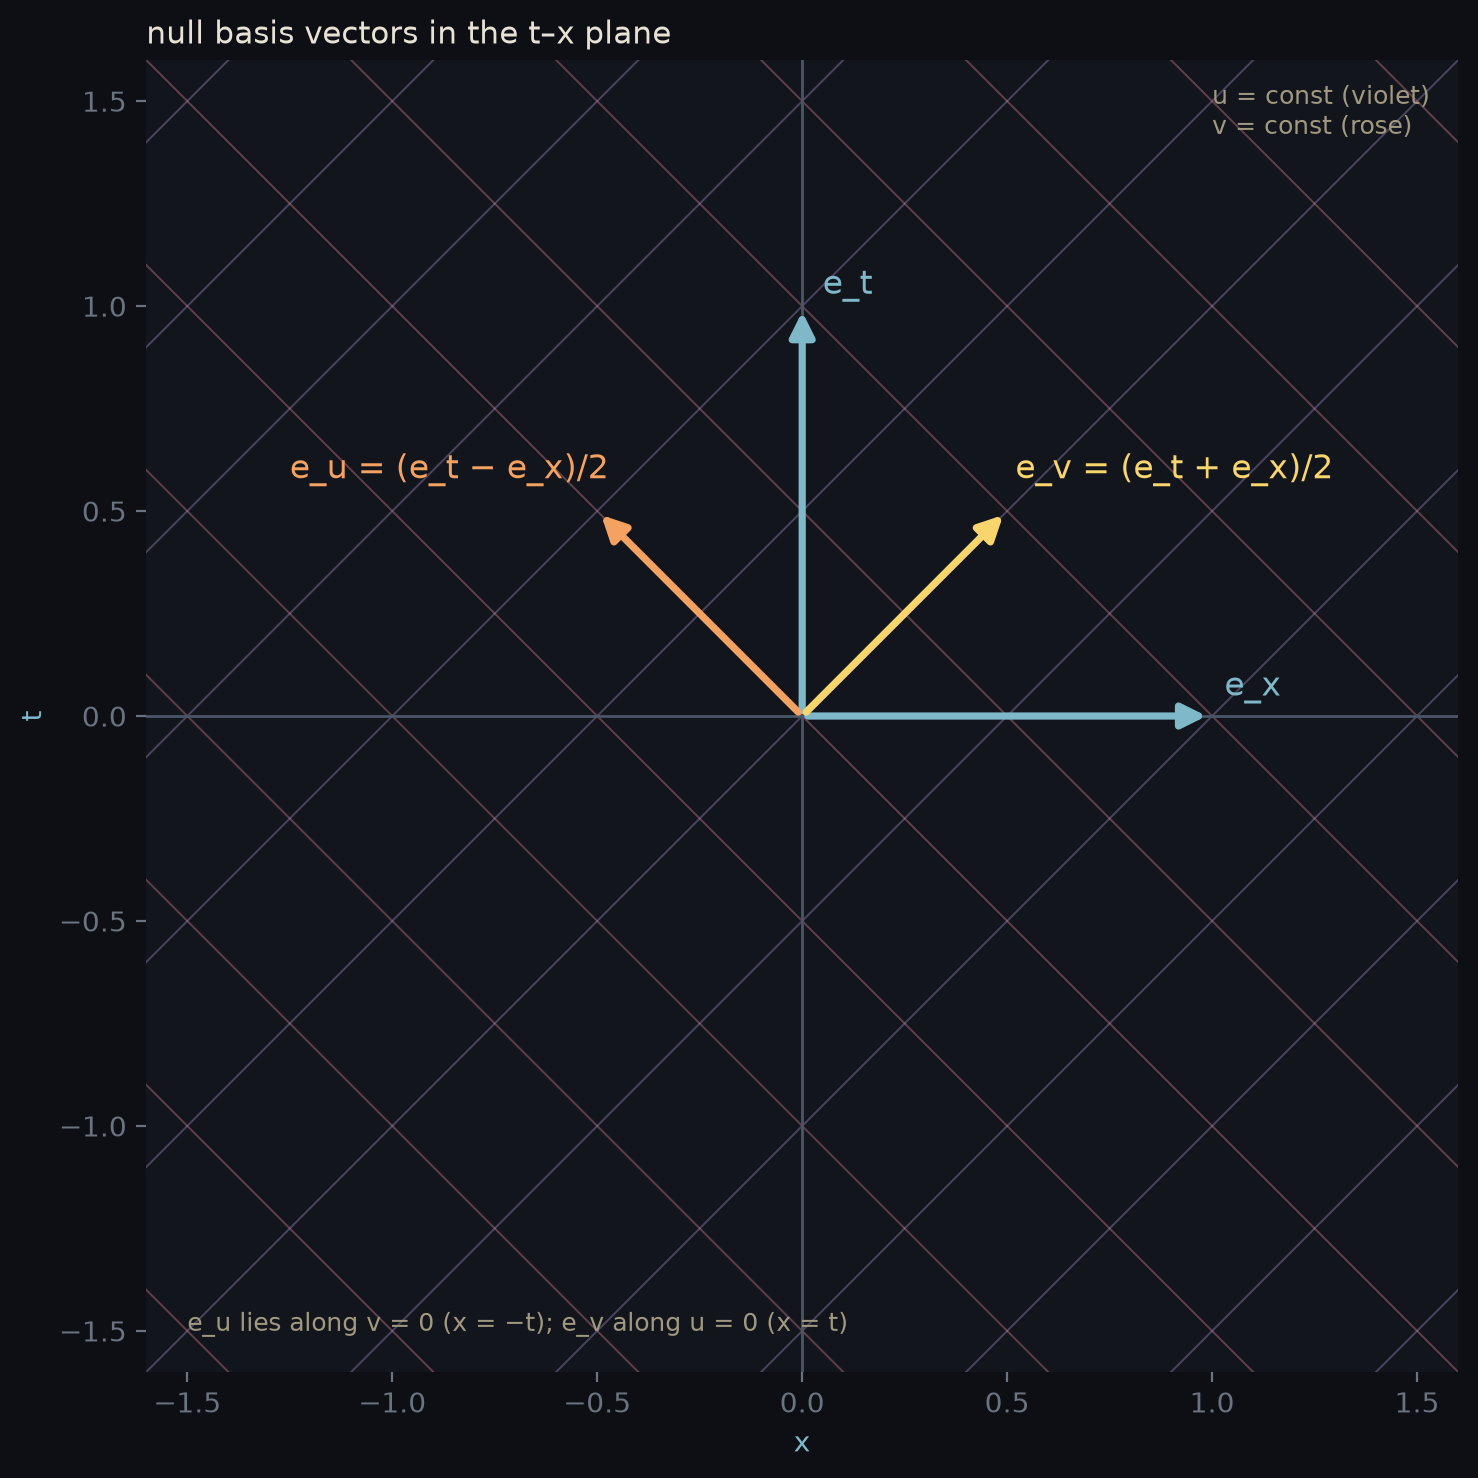

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from schutz_gr.diagrams import COLORS
%config InlineBackend.figure_format = 'retina'

fig, ax = plt.subplots(figsize=(7.5, 7.5)); fig.patch.set_facecolor(COLORS["bg"]); ax.set_facecolor(COLORS["panel"])
L = 1.6; ax.set_xlim(-L, L); ax.set_ylim(-L, L); ax.set_aspect("equal")
s = np.linspace(-3, 3, 2)
for k in np.arange(-3, 3.01, 0.5):                      # u = const and v = const grid lines (null lines)
    ax.plot(s, s + k, color=COLORS["violet"], lw=0.7, alpha=0.35)     # u = t − x = −k  →  t = x + k
    ax.plot(s, -s + k, color=COLORS["rose"], lw=0.7, alpha=0.35)      # v = t + x = k
ax.axhline(0, color=COLORS["axis"], lw=1); ax.axvline(0, color=COLORS["axis"], lw=1)
def arrow(vx, vt, c, lab, off):
    ax.annotate("", xy=(vx, vt), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2.6, mutation_scale=18))
    ax.text(vx + off[0], vt + off[1], lab, color=c, fontsize=12)
arrow(0, 1, COLORS["teal"], "e_t", (0.05, 0.03)); arrow(1, 0, COLORS["teal"], "e_x", (0.03, 0.05))
arrow(-0.5, 0.5, COLORS["amber"], "e_u = (e_t − e_x)/2", (-0.75, 0.08)); arrow(0.5, 0.5, COLORS["gold"], "e_v = (e_t + e_x)/2", (0.02, 0.08))
ax.text(1.0, 1.42, "u = const (violet)\nv = const (rose)", color=COLORS["muted"], fontsize=9)
ax.text(-1.5, -1.5, "e_u lies along v = 0 (x = −t); e_v along u = 0 (x = t)", color=COLORS["muted"], fontsize=9)
ax.set_xlabel("x", color=COLORS["teal"]); ax.set_ylabel("t", color=COLORS["teal"]); ax.tick_params(colors=COLORS["grey"])
ax.set_title("null basis vectors in the t–x plane", color=COLORS["text"], loc="left", fontsize=11)
for sp_ in ax.spines.values(): sp_.set_visible(False)
plt.tight_layout(); plt.show()

## (b) A basis

In $(t, x, y, z)$ components the four vectors are the columns of
$$
\begin{pmatrix}\tfrac12&\tfrac12&0&0\\-\tfrac12&\tfrac12&0&0\\0&0&1&0\\0&0&0&1\end{pmatrix},\qquad \det = \tfrac12\cdot\tfrac12 - \big(-\tfrac12\big)\tfrac12 = \tfrac12 \neq 0 .
$$
Four linearly independent vectors in a 4-dimensional space form a basis. Explicitly, $\vec e_t = \vec e_u + \vec e_v$ and $\vec e_x = \vec e_v - \vec e_u$, so any $\vec A = A^t\vec e_t + A^x\vec e_x + \dots = (A^t - A^x)\vec e_u + (A^t + A^x)\vec e_v + A^y\vec e_y + A^z\vec e_z$. Note $A^u = A^t - A^x$, $A^v = A^t + A^x$: the same as $u, v$ in terms of $t, x$, as it should be for a linear coordinate change.

## (c) Metric components

$g_{\bar\alpha\bar\beta} = \vec e_{\bar\alpha}\cdot\vec e_{\bar\beta}$:
$$
g_{uu} = -\tfrac14 + \tfrac14 = 0,\quad g_{vv} = -\tfrac14 + \tfrac14 = 0,\quad g_{uv} = g_{vu} = -\tfrac12\cdot\tfrac12 + \big(-\tfrac12\big)\tfrac12 = -\tfrac12,
$$
$g_{uy} = g_{uz} = g_{vy} = g_{vz} = 0$, $g_{yy} = g_{zz} = 1$, $g_{yz} = 0$:
$$
\boxed{(g_{\bar\alpha\bar\beta}) = \begin{pmatrix}0&-\tfrac12&0&0\\-\tfrac12&0&0&0\\0&0&1&0\\0&0&0&1\end{pmatrix}}\qquad(\text{order } u, v, y, z),
$$
i.e. $ds^2 = -du\,dv + dy^2 + dz^2$. Check: $-du\,dv = -(dt - dx)(dt + dx) = -dt^2 + dx^2$ ✓. (Also obtainable as $\Lambda^T\eta\Lambda$, Problem 32a.)

The inverse metric has $g^{uv} = -2$, $g^{uu} = g^{vv} = 0$: here $g^{\alpha\beta}$ is **not** numerically equal to $g_{\alpha\beta}$, unlike in an orthonormal frame.

## (d) Null and not orthogonal

$\vec e_u\cdot\vec e_u = g_{uu} = 0$ and $\vec e_v\cdot\vec e_v = g_{vv} = 0$: both null. $\vec e_u\cdot\vec e_v = g_{uv} = -\tfrac12 \neq 0$: not orthogonal. (In fact two null vectors are orthogonal only if they're parallel, so a basis can't contain two orthogonal null vectors.) This is a perfectly good basis, just not an orthonormal one, so $g_{\alpha\beta} \neq \eta_{\alpha\beta}$.

## (e) The one-forms

**Gradients.** $u = t - x$ and $v = t + x$ are linear in $t, x$, so
$$
\boxed{\tilde du = \tilde dt - \tilde dx},\qquad \boxed{\tilde dv = \tilde dt + \tilde dx}.
$$
These are the basis dual to $\{\vec e_u, \vec e_v\}$: $\tilde du(\vec e_u) = \tfrac12 - (-\tfrac12) = 1$, $\tilde du(\vec e_v) = \tfrac12 - \tfrac12 = 0$, $\tilde dv(\vec e_u) = 0$, $\tilde dv(\vec e_v) = 1$ ✓.

**Metric duals.** $\mathbf g(\vec e_u, \cdot)$ has components $(e_u)_\alpha = \eta_{\alpha\beta}e_u^\beta$; with $e_u \to (\tfrac12, -\tfrac12)$ in $(t, x)$, lowering gives $(-\tfrac12, -\tfrac12)$:
$$
\boxed{\mathbf g(\vec e_u, \cdot) = -\tfrac12(\tilde dt + \tilde dx) = -\tfrac12\,\tilde dv},\qquad
\boxed{\mathbf g(\vec e_v, \cdot) = -\tfrac12(\tilde dt - \tilde dx) = -\tfrac12\,\tilde du}.
$$
The one-form associated with $\vec e_u$ is proportional to $\tilde dv$, **not** $\tilde du$. This matches (c): $\mathbf g(\vec e_u, \cdot)$ has components $g_{u\beta}$ on the $\{\tilde du, \tilde dv\}$ basis, i.e. $(g_{uu}, g_{uv}) = (0, -\tfrac12)$. And it confirms the null-normal phenomenon of Problem 21: $\tilde du$ is normal to the null surfaces $u = $ const, and its associated vector $\mathbf g^{-1}(\tilde du) = -2\vec e_v$ lies **in** those surfaces.

In [3]:
import sympy as sp
t, x, u, v = sp.symbols("t x u v", real=True)
eta = sp.diag(-1, 1, 1, 1)
sol = sp.solve([u - (t - x), v - (t + x)], [t, x]); print("t, x in terms of u, v:", sol)
Lam = sp.Matrix(4, 4, lambda m, a: 0)                    # Λ^μ_ᾱ = ∂x^μ/∂x^ᾱ, ᾱ = (u, v, y, z)
for m, xm in enumerate([sol[t], sol[x]]):
    for a, xa in enumerate([u, v]):
        Lam[m, a] = sp.diff(xm, xa)
Lam[2, 2] = Lam[3, 3] = 1
print("(a) e_u, e_v (columns 0, 1) in (t,x,y,z):"); display(Lam)
print("(b) det =", Lam.det())
g = Lam.T * eta * Lam; print("(c) g_{ᾱβ̄} ="); display(g); print("    g^{ᾱβ̄} ="); display(g.inv())
print("(d) e_u·e_u =", g[0, 0], " e_v·e_v =", g[1, 1], " e_u·e_v =", g[0, 1])
du, dv = sp.Matrix([1, -1, 0, 0]), sp.Matrix([1, 1, 0, 0])                    # components on (d̃t, d̃x, d̃y, d̃z)
print("(e) d̃u, d̃v dual to e_u, e_v:", [ (f.T * Lam[:, a])[0] for f in (du, dv) for a in (0, 1)])
print("    g(e_u,·) =", list(eta * Lam[:, 0]), " = −½ d̃v ?", eta * Lam[:, 0] == -dv / 2)
print("    g(e_v,·) =", list(eta * Lam[:, 1]), " = −½ d̃u ?", eta * Lam[:, 1] == -du / 2)

t, x in terms of u, v: {t: u/2 + v/2, x: -u/2 + v/2}
(a) e_u, e_v (columns 0, 1) in (t,x,y,z):


Matrix([
[ 1/2, 1/2, 0, 0],
[-1/2, 1/2, 0, 0],
[   0,   0, 1, 0],
[   0,   0, 0, 1]])

(b) det = 1/2
(c) g_{ᾱβ̄} =


Matrix([
[   0, -1/2, 0, 0],
[-1/2,    0, 0, 0],
[   0,    0, 1, 0],
[   0,    0, 0, 1]])

    g^{ᾱβ̄} =


Matrix([
[ 0, -2, 0, 0],
[-2,  0, 0, 0],
[ 0,  0, 1, 0],
[ 0,  0, 0, 1]])

(d) e_u·e_u = 0  e_v·e_v = 0  e_u·e_v = -1/2
(e) d̃u, d̃v dual to e_u, e_v: [1, 0, 0, 1]
    g(e_u,·) = [-1/2, -1/2, 0, 0]  = −½ d̃v ? True
    g(e_v,·) = [-1/2, 1/2, 0, 0]  = −½ d̃u ? True
